# Analisis Data Produk & Penjualan POS

Notebook ini melakukan proses Exploratory Data Analysis (EDA), Data Cleaning, Feature Engineering, K-Means Clustering, dan Simple Moving Average (SMA) untuk mengklasifikasikan pergerakan penjualan produk dan merekomendasikan jumlah restock.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

## 1. Load Data
Membaca data dari file `transaction_data.csv` dan `product_stock_data.csv`.

In [8]:
# Load Datasets
transactions_df = pd.read_csv('../datasets/transaction_data.csv')
stock_df = pd.read_csv('../datasets/product_stock_data.csv')

print("Transactions Data Shape:", transactions_df.shape)
print("Stock Data Shape:", stock_df.shape)
transactions_df.head()

Transactions Data Shape: (200, 6)
Stock Data Shape: (100, 6)


,date,product_code,product_name,category,price,quantity_sold
0,2026-06-06,PRD00080,Casing UAG Fast Charge,Casing & Cover,440000.0,5
1,2026-06-06,PRD00091,Fleksibel Oppo Pro,Fleksibel & Konektor,150000.0,4
2,2026-06-06,PRD00020,Flashdisk Kingston 32GB,Aksesoris Lainnya,1350000.0,5
3,2026-06-06,PRD00081,Screen Spigen Pro,Screen Protector,400000.0,1
4,2026-06-06,PRD00052,Voucher Axis 30GB,Voucher Internet,130000.0,1


## 2. Data Cleaning
Pembersihan data mencakup penanganan data kosong, duplikat, dan penyeragaman format.

In [9]:
# Menghapus duplikat jika ada
transactions_df.drop_duplicates(inplace=True)
stock_df.drop_duplicates(inplace=True)

# Konversi format tanggal
transactions_df['date'] = pd.to_datetime(transactions_df['date'])

# Membersihkan spasi pada kode produk
transactions_df['product_code'] = transactions_df['product_code'].astype(str).str.strip()
stock_df['product_code'] = stock_df['product_code'].astype(str).str.strip()

print("Missing values in transactions:\n", transactions_df.isnull().sum())
print("\nMissing values in stock:\n", stock_df.isnull().sum())

Missing values in transactions:
 date             0
product_code     0
product_name     0
category         0
price            0
quantity_sold    0
dtype: int64

Missing values in stock:
 product_code     0
product_name     0
category         0
current_stock    0
minimum_stock    0
selling_price    0
dtype: int64


## 3. Exploratory Data Analysis (EDA)
Menganalisis statistik, jumlah terjual, dan pola penjualan.

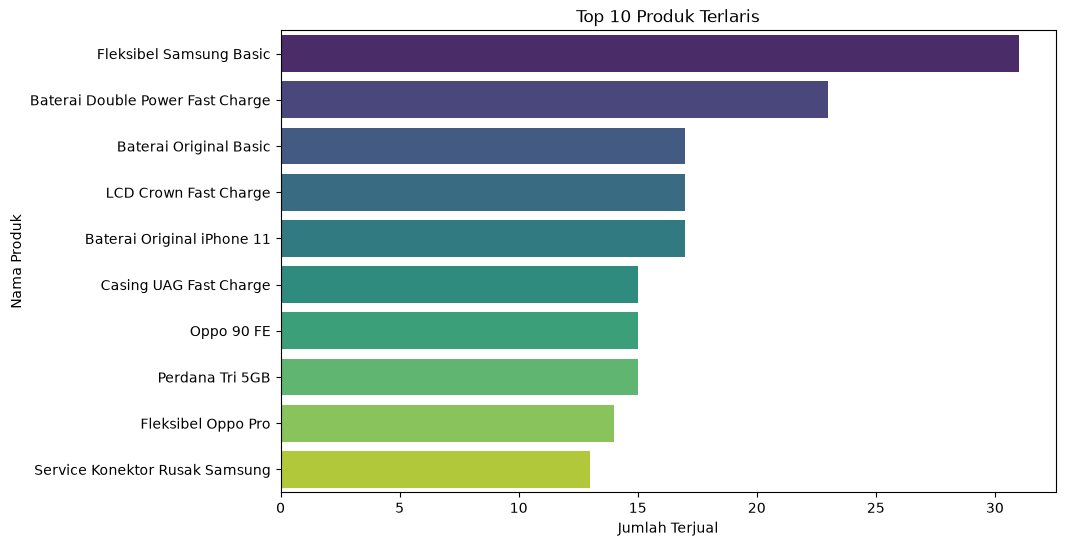

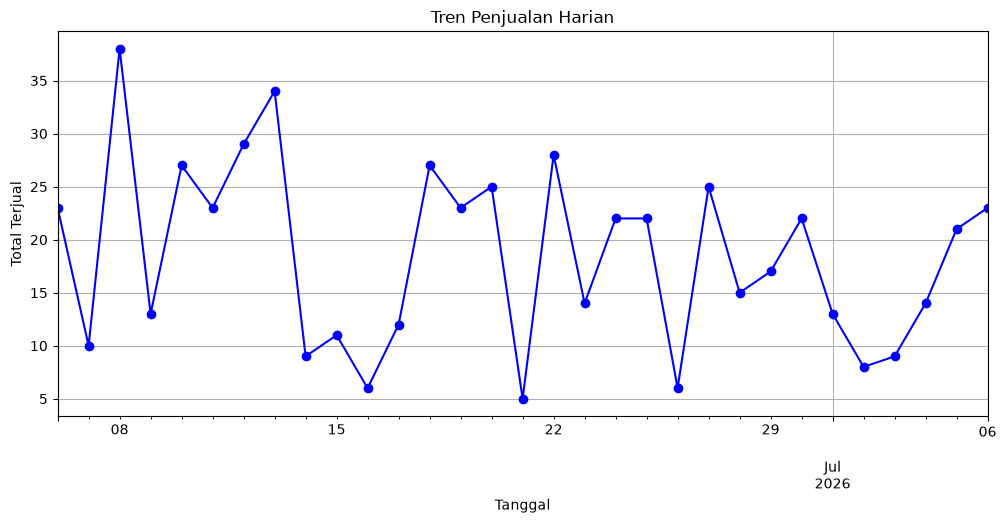

In [10]:
# Produk Terlaris
top_selling = transactions_df.groupby('product_name')['quantity_sold'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_selling.values, y=top_selling.index, palette='viridis')
plt.title('Top 10 Produk Terlaris')
plt.xlabel('Jumlah Terjual')
plt.ylabel('Nama Produk')
plt.show()

# Tren Penjualan Harian
sales_trend = transactions_df.groupby('date')['quantity_sold'].sum()
plt.figure(figsize=(12, 5))
sales_trend.plot(kind='line', color='blue', marker='o')
plt.title('Tren Penjualan Harian')
plt.xlabel('Tanggal')
plt.ylabel('Total Terjual')
plt.grid()
plt.show()

## 4. Feature Engineering
Membuat fitur-fitur baru seperti total penjualan, frekuensi, periode jualan, rata-rata penjualan.

In [11]:
# Agregasi transaksi per produk
product_sales = transactions_df.groupby('product_code').agg(
    total_quantity_sold=('quantity_sold', 'sum'),
    transaction_frequency=('quantity_sold', 'count'),
    first_sale_date=('date', 'min'),
    last_sale_date=('date', 'max')
).reset_index()

# Hitung periode penjualan dan rata-rata per hari
product_sales['sales_period_days'] = (product_sales['last_sale_date'] - product_sales['first_sale_date']).dt.days
product_sales['sales_period_days'] = product_sales['sales_period_days'].apply(lambda x: x if x > 0 else 1) # Minimal 1 hari
product_sales['avg_daily_sales'] = product_sales['total_quantity_sold'] / product_sales['sales_period_days']

# Gabungkan dengan Data Stok. Pastikan produk tanpa penjualan (dead stock) tetap ada.
merged_df = pd.merge(stock_df, product_sales, on='product_code', how='left')

# Isi NaN untuk produk yang tidak pernah terjual
merged_df['total_quantity_sold'] = merged_df['total_quantity_sold'].fillna(0)
merged_df['transaction_frequency'] = merged_df['transaction_frequency'].fillna(0)
merged_df['avg_daily_sales'] = merged_df['avg_daily_sales'].fillna(0)
merged_df['current_stock'] = pd.to_numeric(merged_df['current_stock'], errors='coerce').fillna(0)

merged_df.head()

,product_code,product_name,category,current_stock,minimum_stock,selling_price,total_quantity_sold,transaction_frequency,first_sale_date,last_sale_date,sales_period_days,avg_daily_sales
0,PRD00001,iPhone 13 128GB,Smartphone Baru,97,5,2250000.0,0.0,0.0,NaT,NaT,NaN,0.000000
1,PRD00002,Samsung Galaxy A54 5G,Smartphone Baru,53,5,2700000.0,9.0,2.0,2026-06-06,2026-06-19,13.0,0.692308
2,PRD00003,Xiaomi Redmi Note 12,Smartphone Baru,11,5,4140000.0,5.0,1.0,2026-06-23,2026-06-23,1.0,5.000000
3,PRD00004,Oppo Reno 10,Smartphone Baru,78,5,1400000.0,1.0,1.0,2026-06-20,2026-06-20,1.0,1.000000
4,PRD00005,Vivo V27,Smartphone Baru,63,5,4680000.0,2.0,1.0,2026-06-13,2026-06-13,1.0,2.000000


## 5. K-Means Clustering
Mengelompokkan produk menjadi 3 kategori (Low, Medium, High Movement).

Distribusi Pergerakan Produk:
movement_category
Low       49
Medium    31
High      20
Name: count, dtype: int64


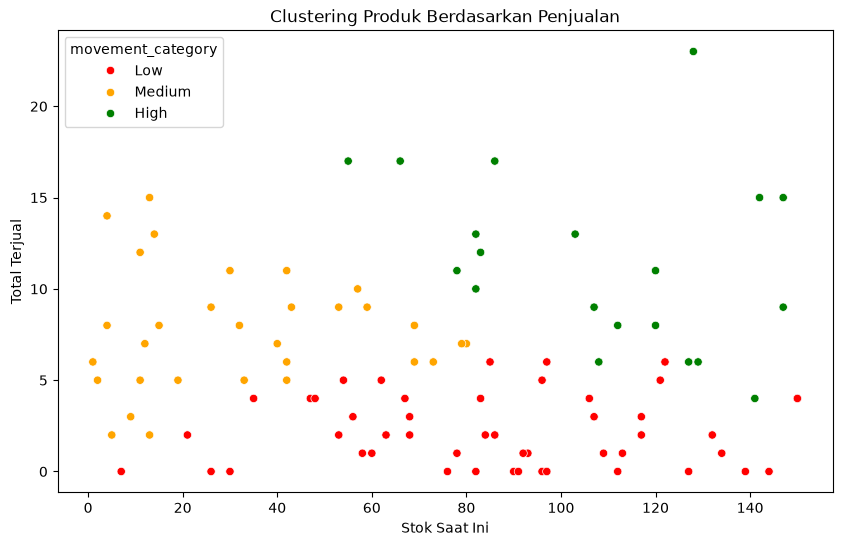

In [12]:
from sklearn.preprocessing import StandardScaler

# Fitur untuk clustering
clustering_features = merged_df[['total_quantity_sold', 'transaction_frequency', 'current_stock']]

# Standarisasi data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(clustering_features)

# K-Means dengan 3 cluster
kmeans = KMeans(n_clusters=3, random_state=42)
merged_df['cluster'] = kmeans.fit_predict(scaled_features)

# Menentukan label berdasarkan rata-rata penjualan tiap cluster
cluster_means = merged_df.groupby('cluster')['total_quantity_sold'].mean().sort_values()
cluster_mapping = {
    cluster_means.index[0]: 'Low',
    cluster_means.index[1]: 'Medium',
    cluster_means.index[2]: 'High'
}
merged_df['movement_category'] = merged_df['cluster'].map(cluster_mapping)

print("Distribusi Pergerakan Produk:")
print(merged_df['movement_category'].value_counts())

# Visualisasi hasil clustering
plt.figure(figsize=(10, 6))
sns.scatterplot(x='current_stock', y='total_quantity_sold', hue='movement_category', data=merged_df, palette={'Low':'red', 'Medium':'orange', 'High':'green'})
plt.title('Clustering Produk Berdasarkan Penjualan')
plt.xlabel('Stok Saat Ini')
plt.ylabel('Total Terjual')
plt.show()

## 6. Simple Moving Average (SMA)
Menghitung estimasi kebutuhan stok berdasarkan rata-rata penjualan. Jika estimasi kebutuhan (misal untuk 7 hari) + stok minimal lebih besar dari stok saat ini, maka perlu restock.

In [13]:
# Estimasi kebutuhan (demand) untuk 7 hari ke depan
sma_period = 7
merged_df['estimated_demand_7d'] = np.ceil(merged_df['avg_daily_sales'] * sma_period)

# Rekomendasi Restock
# Rumus: Kebutuhan 7 hari + Minimum Stock - Stok Saat ini
merged_df['restock_recommendation'] = merged_df.apply(
    lambda row: max(0, (row['estimated_demand_7d'] + row['minimum_stock']) - row['current_stock']), 
    axis=1
)

# Tampilkan produk yang butuh restock
restock_needed = merged_df[merged_df['restock_recommendation'] > 0].sort_values(by='restock_recommendation', ascending=False)
restock_needed[['product_name', 'current_stock', 'estimated_demand_7d', 'minimum_stock', 'restock_recommendation']].head(10)

,product_name,current_stock,estimated_demand_7d,minimum_stock,restock_recommendation
2,Xiaomi Redmi Note 12,11,35.0,5,29.0
62,Voucher Indosat 10GB,19,35.0,5,21.0
26,Charger Baseus Premium,9,21.0,5,17.0
73,Fleksibel Realme Pro,5,14.0,5,14.0
27,Pulsa Indosat 20GB,1,6.0,5,10.0
70,Baterai Mcom Fast Charge,12,17.0,5,10.0
52,Fleksibel Samsung Basic,4,6.0,5,7.0
64,Casing Spigen Pro,2,2.0,5,5.0
87,Baterai Rakkipanda Basic,4,4.0,5,5.0


## 7. Simpan Hasil Analisis
Menyimpan data hasil klasifikasi K-Means dan rekomendasi restock SMA.

In [14]:
output_columns = [
    'product_code', 'product_name', 'category', 'current_stock', 'minimum_stock',
    'total_quantity_sold', 'transaction_frequency', 'avg_daily_sales',
    'movement_category', 'restock_recommendation'
]
final_results = merged_df[output_columns]

# Menyimpan hasil
output_path = '../datasets/product_analysis_results.csv'
final_results.to_csv(output_path, index=False)
print(f"Analisis selesai. Hasil disimpan di: {output_path}")

final_results.head()

Analisis selesai. Hasil disimpan di: ../datasets/product_analysis_results.csv


,product_code,product_name,category,current_stock,minimum_stock,total_quantity_sold,transaction_frequency,avg_daily_sales,movement_category,restock_recommendation
0,PRD00001,iPhone 13 128GB,Smartphone Baru,97,5,0.0,0.0,0.000000,Low,0.0
1,PRD00002,Samsung Galaxy A54 5G,Smartphone Baru,53,5,9.0,2.0,0.692308,Medium,0.0
2,PRD00003,Xiaomi Redmi Note 12,Smartphone Baru,11,5,5.0,1.0,5.000000,Medium,29.0
3,PRD00004,Oppo Reno 10,Smartphone Baru,78,5,1.0,1.0,1.000000,Low,0.0
4,PRD00005,Vivo V27,Smartphone Baru,63,5,2.0,1.0,2.000000,Low,0.0
